Task 1:

Formal Classification Problem:

The goal of this project is to build a classification model that is able to predict whether a client will experience a crisis within 90 days of screening. The target variable is crisis_within_90_days, with two possible outcomes: crisis and no_crisis.

The model will use the information that was collected during the community health screenings to estimate the likelihood of a future crisis. The dataset contains 2,400 records with 2,048 no_crisis (85.3%) cases and 352 (14.7%) crisis cases. Since there is a class imbalance, the model should evaluate on how well it can identify crisis cases rather than relying on the overall accuracy alone from the information that was collected.

Train/Validate/Splitting Test:

The dataset will be divided into training, validation, and test using the 70/15/15 split. The training set will contain 70% of the records, while the validation and test sets will both contain 15%. We will be using a stratified splitting to maintain similar proportions of crisis and no_crisis cases for each set. This is important since the dataset is unbalanced with only 14.7% labeled crisis. The test set is held out until the end is to provide an unbiased measure of how well the model can perform with the data it has not used during the training or model selection. The validation set will be used to compare the models and adjust the prediction thresholds. Keeping the test set untouched until the end helps prevent bias within the final evaluation and provides a more reliable estimate of how the model may perform with the new data.

In [4]:
import pandas as pd
from numpy.random.mtrand import logistic
from sklearn.model_selection import train_test_split

df = pd.read_csv("community_risk_screening_train.csv")

print("Original Dataset Size:", df.shape)

Original Dataset Size: (2400, 12)


In [5]:
#Split the Dataset, Use 70% for Training, 15% for Validation, and 15% for Testing
#Separate the Target Variable from the Input Features
x = df.drop(columns=["crisis_within_90_days"])
y = df["crisis_within_90_days"]

#Split off 30% for Validation and Testing
x_train, x_temp, y_train, y_temp = train_test_split (
    x, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

#Split the Remaining 30% Equally into Validation and Test Sets
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

#Display Size of Each Set
print("Training Set:", x_train.shape[0], "records")
print("Validation Set:", x_val.shape[0], "records")
print("Test Set:", x_test.shape[0], "records")

Training Set: 1680 records
Validation Set: 360 records
Test Set: 360 records


In [8]:
#Check Class Proportions in Each Set
#Verify Stratified Splitting Preserved the Class Balance

print("Training Set Class Proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation Set Class Proportions:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTest Set Class Proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training Set Class Proportions:
crisis_within_90_days
no_crisis    0.854
crisis       0.146
Name: proportion, dtype: float64

Validation Set Class Proportions:
crisis_within_90_days
no_crisis    0.853
crisis       0.147
Name: proportion, dtype: float64

Test Set Class Proportions:
crisis_within_90_days
no_crisis    0.853
crisis       0.147
Name: proportion, dtype: float64


Data Splitting Results:

The dataset was divided using the 70/15/15 split. The training set contains 1,680 records while the validation and test sets each contain 360 records. The stratified splitting was used to maintain the similar proportions of crisis and no_crisis across all three sets. The results showed that approximately 85.3% of records were labeled no_crisis and 14.7% were labeled crisis in each set. This confirms that the class proportions were preserved during splitting.

The training set will be used to train the models, the validation set will be used to compare model performance and adjust prediction thresholds, and the test set will be reserved for final evaluation after model decisions are complete.

Evaluation Metrics:

Since the dataset is imbalanced, the accuracy alone is not enough to evaluate the models. The model could achieve a high accuracy at predicting the majority class, no_crisis, while failing to identify the people who is going to experience a crisis.

The primary evaluation metrics for this project will be recall, precision, and F1-score.
- Recall: Measures how well the model identifies the actual crisis cases the model correctly identifies, which is important because missing someone who needs a follow up support could have serious consequences.
- Precision: Measures how many people are predicted to experience an actual crisis, this will help us understand how often the outreach resources may be directed toward people who have no experience a crisis.
- F1-Score: Combines precision and recall into one score to help compare the models within this imbalanced dataset while considering both missed crisis cases and incorrect crisis predictions.

A confusion matrix will also be used to show the number of correct and incorrect predictions. This will help identify errors, especially cases where the model predicts no_crisis for someone who actually experiences a crisis.

Accuracy may be reported as a secondary metric, but it will not be used alone since the dataset contains more no_crisis than crisis. These metrics will help evaluate whether the models can identify potential crisis cases while supporting outreach prioritization and professional judgment.

Task 2:

Prepare the Dataset:
The target variable is crisis_within_90_days. Both baseline models will be using the same eight screening features: age_at_screening, region, housing_status, prior_crisis_events_12mo, phq2_score, substance_use_flag, support_type, and days_since_last_contact. client_screening_id, outreach_followup_tier, and coordinator_intake_notes will be excluded from the initial models because they are an identifier, a potential source of data leakage, and unprocessed text, respectively. Missing values and categorical features will be handled during model preprocessing.

In [6]:
#Eight Features for Both Baseline Models
feature_columns = [
    "age_at_screening",
    "region",
    "housing_status",
    "prior_crisis_events_12mo",
    "phq2_score",
    "substance_use_flag",
    "primary_support_type",
    "days_since_last_contact"
]
#Separate Selected Features from Target
x = df[feature_columns]
y = df["crisis_within_90_days"]

#Create Training Set at 70% and Temporary Set at 30%
from sklearn.model_selection import train_test_split

x_train, x_temp, y_train, y_temp = train_test_split(
    x, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

#Divide the Temporary Set Equally into Validation and Test Sets
x_val, x_test, y_val, y_test = train_test_split(
    x_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

#Check Size
print("Training Records:", len(x_train))
print("Validation Records:", len(x_val))
print("Test Records:", len(x_test))
print("Selected Features:", len(feature_columns))

Training Records: 1680
Validation Records: 360
Test Records: 360
Selected Features: 8


In [6]:
from sklearn.metrics import recall_score, precision_score, f1_score

#Predict Crisis if Person had one Prior to Crisis Event
y_val_rule = (x_val["prior_crisis_events_12mo"] >= 1).astype(int)

#Convert the Actual Validation Labels to 1 for Crisis and 0 for no_crisis
y_val_actual = (y_val == "crisis").astype(int)

#Calculate Evaluation Metrics
recall = recall_score(y_val_actual, y_val_rule, zero_division=0)
precision = precision_score(y_val_actual, y_val_rule, zero_division=0)
f1 = f1_score(y_val_actual, y_val_rule, zero_division=0)

#Display Results
print("Rule Based Results:")
print("Recall:", recall, 3)
print("Precision:", precision, 3)
print("F1 Score:", f1, 3)

Rule Based Results:
Recall: 0.9622641509433962 3
Precision: 0.159375 3
F1 Score: 0.2734584450402145 3


Rule Based Results:

The rule based baseline predicts someone having a crisis prior to the crisis event within the previous 12 months. On the validation set, the model achieved a recall of 0.962, precision of 0.159, and F1 score of 0.273. The high recall indicates that the rule identified approximately 96.2% of actual crisis cases. But, the low precision indicates that only about 15.9% of people predicted to experience a crisis actually experienced one. This means the rule may identify most people who need additional support, but it also flags many people who do not experience a crisis within the next 90 days. The results demonstrate a trade off between identifying as many crisis cases as possible and avoiding unnecessary outreach. The rule based baseline provides a simple starting point for comparison with the logistic regression model.

Logistic Regression Baseline:

Logistic regression is a classification model that estimates the likelihood of a crisis based on the selected screening features. This baseline will be evaluated using the same validation set and metrics as the rule-based model.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, f1_score

#Separate Numerical and Categorical Features
numeric_features = [
    "age_at_screening",
    "prior_crisis_events_12mo",
    "phq2_score",
    "days_since_last_contact"
]
categorical_features = [
    "region",
    "housing_status",
    "substance_use_flag",
    "primary_support_type"
]

#Prepare Numerical Features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler()),
])

#Prepare Categorical Features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

#Combine Both Steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

#Create the Logistic Regression Model
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

#Train Using Only the Training Data
logistic_model.fit(x_train, y_train)

#Predict Outcomes for Validation Data
y_val_logistic = logistic_model.predict(x_val)

#Calculate the Validation Metrics
recall = recall_score(y_val, y_val_logistic, pos_label="crisis", zero_division=0)
precision = precision_score(y_val, y_val_logistic, pos_label="crisis", zero_division=0)
f1 = f1_score(y_val, y_val_logistic, pos_label="crisis", zero_division=0)

#Display Results
print("Logistic Regression Results:")
print("Recall:", round(recall, 3))
print("Precision:", round(precision, 3))
print("F1 Score:", round(f1, 3))

Logistic Regression Results:
Recall: 0.774
Precision: 0.512
F1 Score: 0.617


Logistic Regression Results:

For the validation set the logistic regression baseline achieved a recall of 0.774, precision of 0.512, and F1 score of 0.617. Compared this with the rule base baseline, the logistic regression had lower recall but higher precision and a higher f1 score. The rule base model achieved a recall of 0.962, this means that it identified a larger proportion of actual crisis cases. In comparison with the logistic regression it achieved a 0.512 precision, meaning positive predictions were more likely to identify actual crisis cases. These results suggest that logistic regression may reduce false alarms while maintaining reasonable crisis detection. However, its lower recall means it missed more actual crisis cases than the rule based model. Since missing someone who needs timely support is an important concern, both models' trade offs should be considered before selecting a preferred model.

### Baseline Model Comparison

| Model | Recall | Precision | F1 Score | Failure Mode |
|---|---:|---:|---:|---|
| Rule Based | 0.962 | 0.159 | 0.273 | Low precision means it flags many people who did not experience a crisis, potentially overwhelming caseworkers with false alarms. |
| Logistic Regression | 0.774 | 0.512 | 0.617 | Lower recall means it misses more actual crisis cases, potentially leaving some people without timely follow-up support. |

**Summary:** Logistic regression achieves a better balance between recall and precision, with a higher F1 score, but its missed crisis cases remain an important concern.

**Threshold Note**: At a threshold of 0.12, the logistic regression achieved 0.887 recall and 0.184 precision, illustrating the trade-off between identifying crisis cases and reducing false alarms.

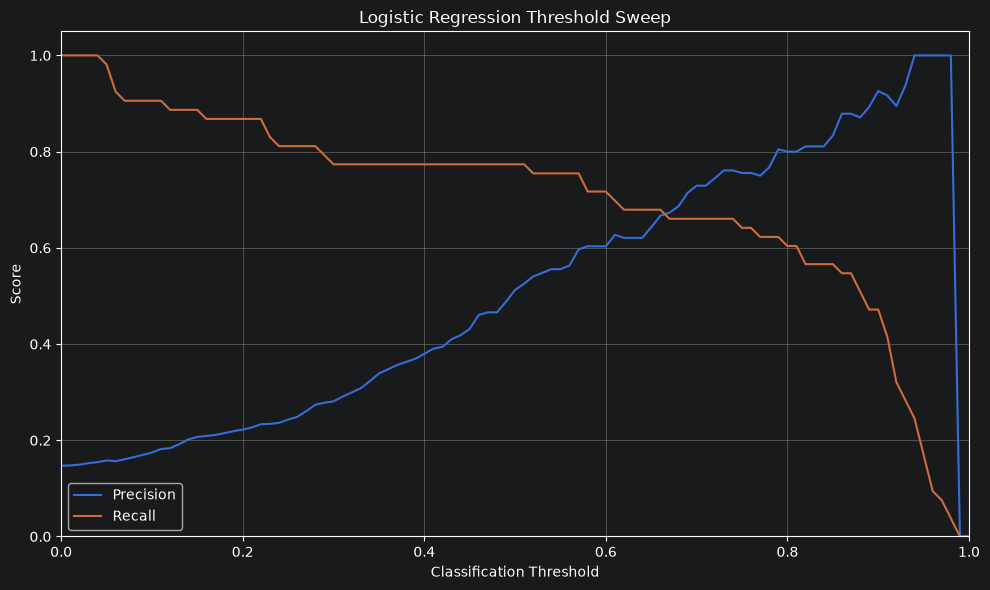

Threshold-Sweep Plot Saved to: C:\Users\zyg98\PycharmProjects\Intern\figures\logistic_regression_threshold_sweep.png


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.metrics import precision_score, recall_score

#Get the Predicted Probability of a Crisis
crisis_index = list(logistic_model.classes_).index("crisis")
y_val_probabilities = logistic_model.predict_proba(x_val)[:, crisis_index]

#Test the Thresholds from 0.00 to 1.00 in the Steps of 0.01
thresholds = np.linspace(0, 1, 101)

precision_values = []
recall_values = []

#Calculate the Precision and Recall at Each Threshold
for threshold in thresholds:
    y_val_predictions = np.where(
        y_val_probabilities >= threshold, "crisis", "no_crisis"
    )
    precision_values.append(
        precision_score(y_val, y_val_predictions, pos_label="crisis", zero_division=0)
    )
    recall_values.append(
        recall_score(y_val, y_val_predictions, pos_label="crisis", zero_division=0)
    )

#Plot Precision and Recall
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision_values, label="Precision")
plt.plot(thresholds, recall_values, label="Recall")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Logistic Regression Threshold Sweep")
plt.xlim(0, 1)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.tight_layout()

#Save Plot in Project Folder
os.makedirs("figures", exist_ok=True)
plot_path = os.path.abspath(
    os.path.join("figures", "logistic_regression_threshold_sweep.png")
)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")

plt.show()

print("Threshold-Sweep Plot Saved to:", plot_path)

In [10]:
#Find Where Recall Drops Below 0.90
for threshold, recall, precision in zip(
    thresholds, recall_values, precision_values
):
    if recall < 0.90:
        print("First Threshold Where Recall Drops Below 0.90")
        print("Threshold:", round(threshold, 2))
        print("Recall:", round(recall, 3))
        print("Precision:", round(precision, 3))
        break

First Threshold Where Recall Drops Below 0.90
Threshold: 0.12
Recall: 0.887
Precision: 0.184


Threshold Sweep Plot Interpretation:

The threshold sweep plot shows us how the classification threshold affects precision and recall for the logistic regression model. Lower thresholds generally identify more potential crisis cases, increasing the recall but can produce more false alarms. However, higher thresholds generally reduce the number of positive predictions which can improve precision but increase the number of missed crisis cases.

At a classification threshold of 0.12, the recall drops below 0.90 to 0.887, while the precision is 0.184. This means the model identifies approximately 88.7% of actual crisis cases, while 18.4% of positive predictions are actual crisis cases. Lowering the threshold helps capture more potential crisis cases but can also increase more false alarms. But at the same time raising it can reduce false alarms but comes with the risk to miss more crisis cases.

Task 3:

Baseline Scorecard Narrative:

The two baseline models were evaluated on the validation set to predict whether a person would experience a crisis within 90 days. The models were compared using recall, precision and F1 score since identifying the crisis cases is important but so are false alarms.

The rule base baseline predicted a crisis when a person had at least one prior crisis event within the previous 12 months. It achieved a recall of 0.962, precision of 0.159 and F1 score of 0.273. Having a high recall means it identified most of the actual crisis cases, but its low precision means many people were flagged by the rule did not experience a crisis within the 90 days. This could lead to having an unnecessary outreach and increase the workload for caseworkers.

The logistic regression baseline achieved a recall of 0.774, precision of 0.512, and a F1 score of 0.617. Comparing this with the rule based baseline, it had a lower recall but a higher precision and F1 score. This suggests that the logistic regression provides a better balance between identifying the crisis cases and also reducing false alarms. However, having the lower recall means it missed more actual crisis cases.

Overall, the logistic regression is the stronger baseline based on its validation F1 score and precision. However, neither of these model should be considered ready for the real world use base on these results alone. Further evaluation is needed to understand missed crisis cases, false alarms and effect of missing data and potential data leakage.